In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

In [2]:
engine = create_engine(
    "mysql+pymysql://root@localhost:3306/climate_watch"
)
df_global = pd.read_sql("SELECT * FROM GlobalTemperatures", con=engine, parse_dates=["dt"])

Text(0.5, 1.0, 'Minimum Land Temperature Uncertainty')

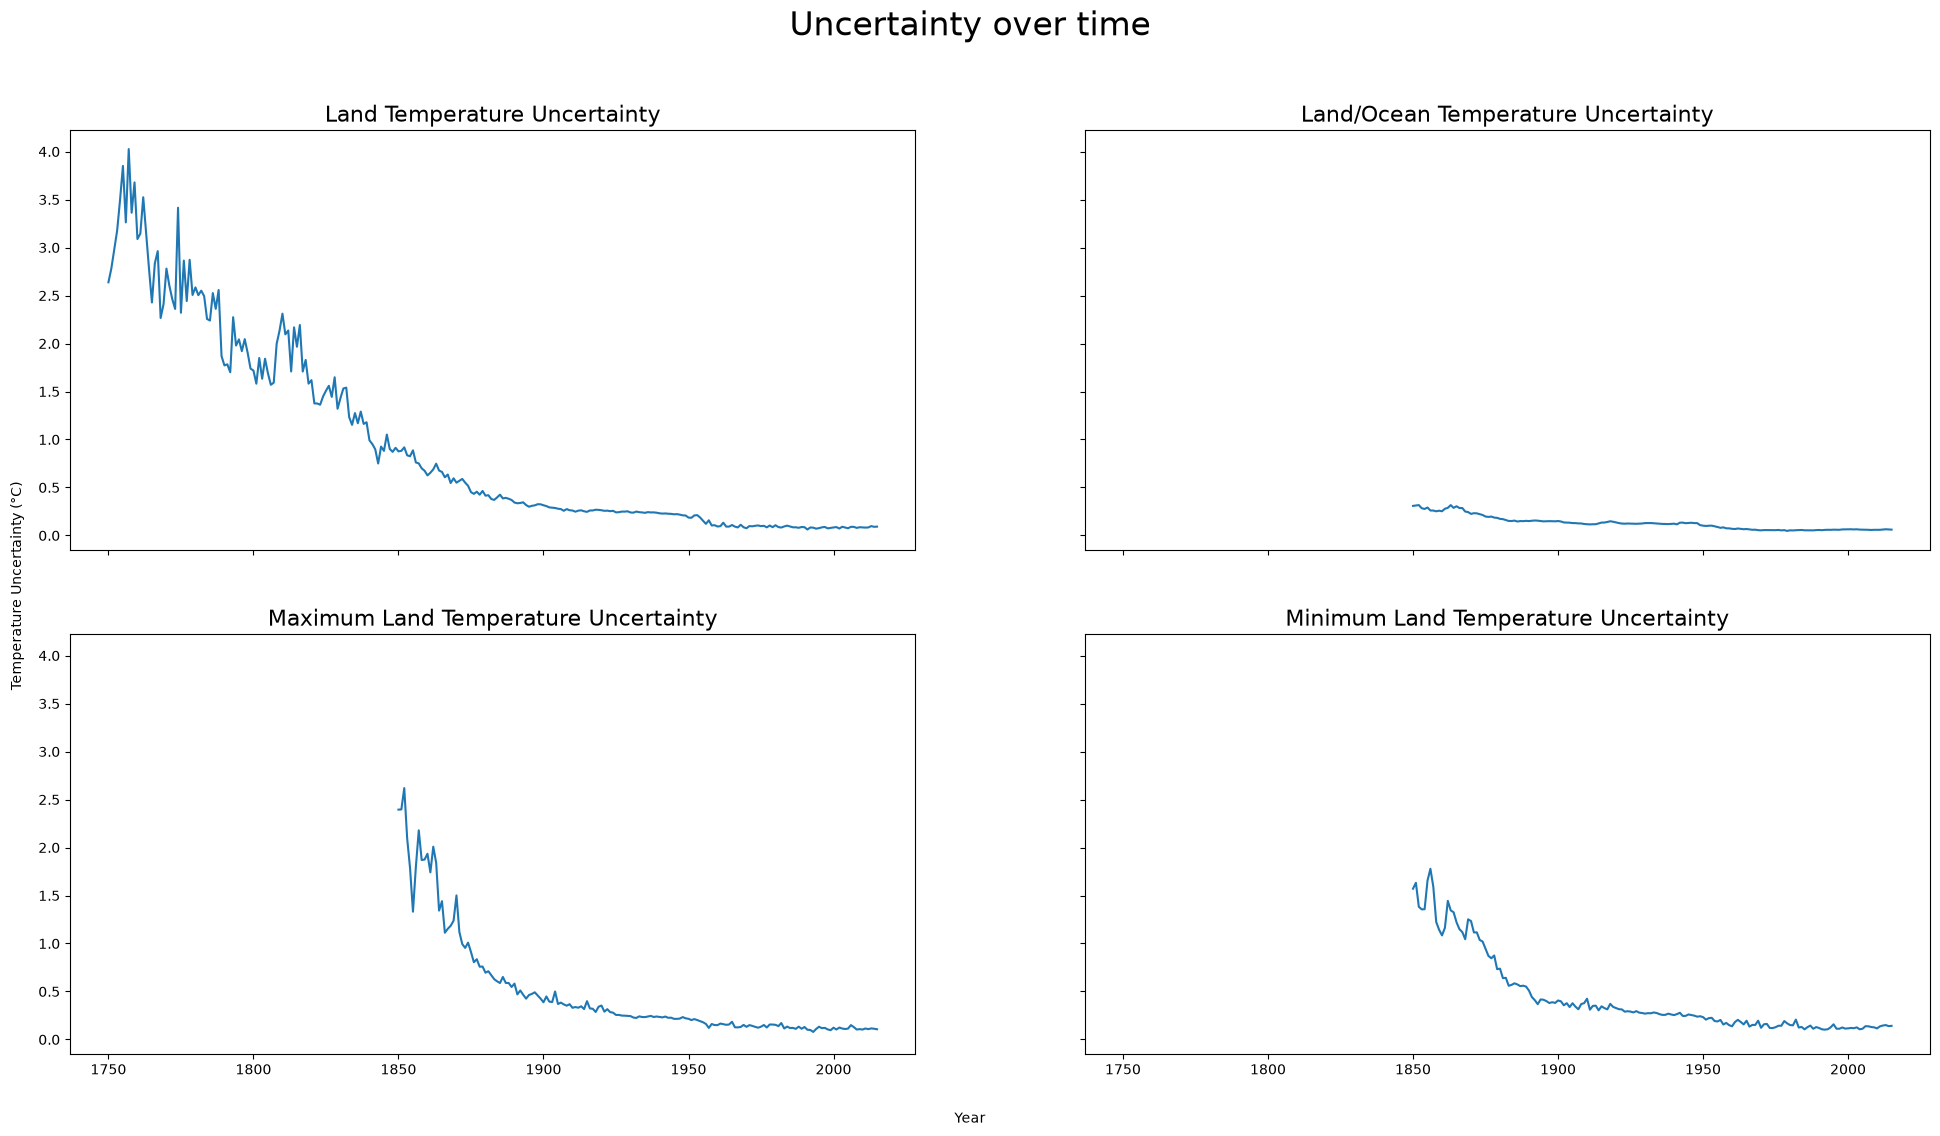

In [3]:
# Gemiddelde temp per jaar
df_global["year"] = df_global["dt"].dt.year
df_global_yearly = df_global.drop(columns="dt").groupby(["year"], as_index=False).mean()
df_plot = df_global_yearly[["year", "LandAverageTemperatureUncertainty", "LandMaxTemperatureUncertainty", "LandMinTemperatureUncertainty", "LandAndOceanAverageTemperatureUncertainty"]]

fig, ax = plt.subplots(2, 2, figsize=(24,12), sharey=True, sharex=True)
fig.suptitle("Uncertainty over time", fontsize=24)
fig.supylabel("Temperature Uncertainty (°C)", x=0.1, fontsize=10)
fig.supxlabel("Year", y=0.05, fontsize=10)

ax[0,0].plot(df_plot["year"], df_plot["LandAverageTemperatureUncertainty"])
ax[0,0].set_title("Land Temperature Uncertainty", fontsize=16)

ax[0,1].plot(df_plot["year"], df_plot["LandAndOceanAverageTemperatureUncertainty"])
ax[0,1].set_title("Land/Ocean Temperature Uncertainty", fontsize=16)

ax[1,0].plot(df_plot["year"], df_plot["LandMaxTemperatureUncertainty"])
ax[1,0].set_title("Maximum Land Temperature Uncertainty", fontsize=16)

ax[1,1].plot(df_plot["year"], df_plot["LandMinTemperatureUncertainty"])
ax[1,1].set_title("Minimum Land Temperature Uncertainty", fontsize=16)

Text(0.5, 1.0, 'Minimum Land Temperature Uncertainty')

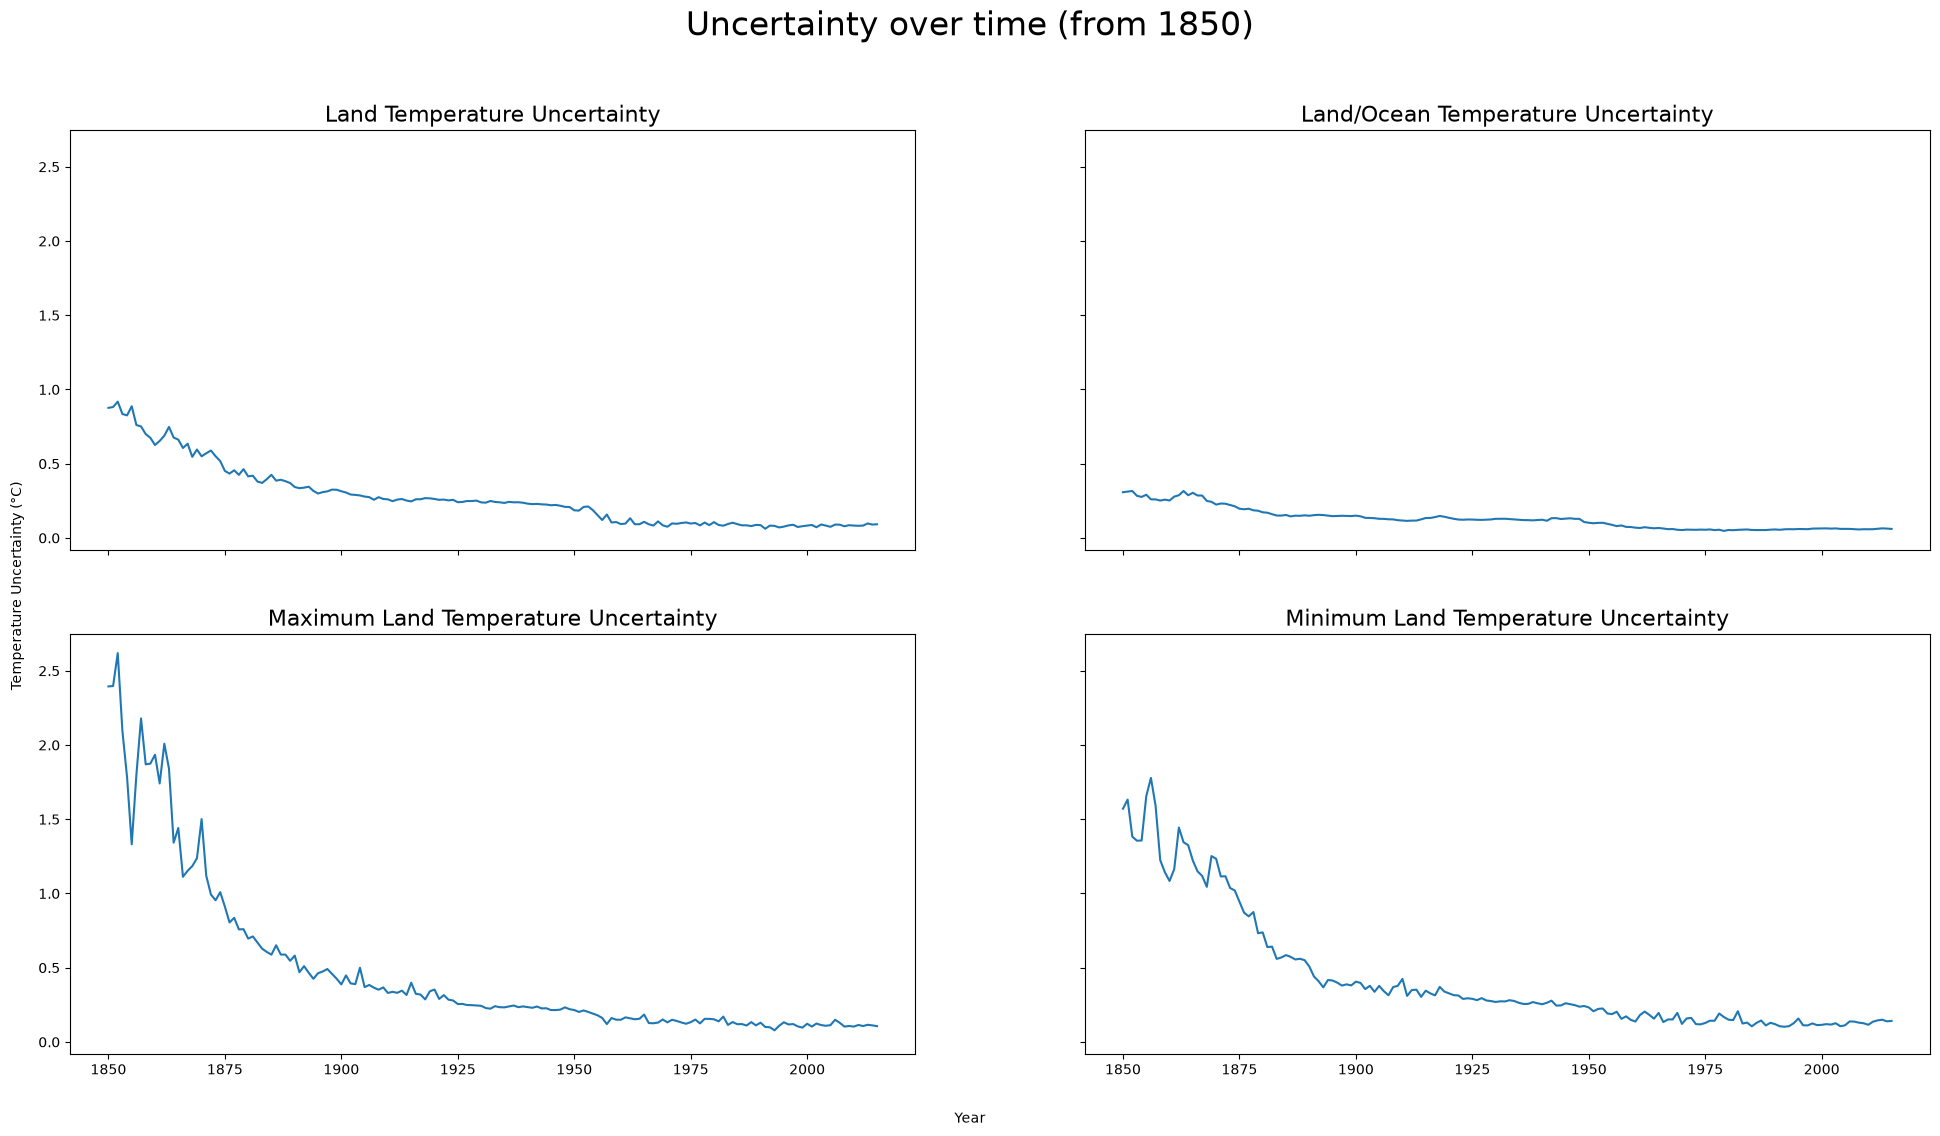

In [4]:
# Vind verband tussen onzekerheid en tijd van land data
df_plot_1850 = df_global_yearly[[
    "year", 
    "LandAverageTemperatureUncertainty", 
    "LandMaxTemperatureUncertainty", 
    "LandMinTemperatureUncertainty", 
    "LandAndOceanAverageTemperatureUncertainty"
    ]][
        df_global_yearly["year"] >= 1850
    ]

fig, ax = plt.subplots(2, 2, figsize=(24,12), sharey=True, sharex=True)
fig.suptitle("Uncertainty over time (from 1850)", fontsize=24)
fig.supylabel("Temperature Uncertainty (°C)", x=0.1, fontsize=10)
fig.supxlabel("Year", y=0.05, fontsize=10)

ax[0,0].plot(df_plot_1850["year"], df_plot_1850["LandAverageTemperatureUncertainty"])
ax[0,0].set_title("Land Temperature Uncertainty", fontsize=16)

ax[0,1].plot(df_plot_1850["year"], df_plot_1850["LandAndOceanAverageTemperatureUncertainty"])
ax[0,1].set_title("Land/Ocean Temperature Uncertainty", fontsize=16)

ax[1,0].plot(df_plot_1850["year"], df_plot_1850["LandMaxTemperatureUncertainty"])
ax[1,0].set_title("Maximum Land Temperature Uncertainty", fontsize=16)

ax[1,1].plot(df_plot_1850["year"], df_plot_1850["LandMinTemperatureUncertainty"])
ax[1,1].set_title("Minimum Land Temperature Uncertainty", fontsize=16)